# Inference on supplied validation

Predict rates for all 12,000 rows of `validation.csv` using the saved full-train model. Actual rates are unavailable, so this notebook displays prediction distributions and temporal patterns without accuracy metrics. No fitting or API calls are required: preprocessing and city/route references come from the saved bundle.

In [1]:
from pathlib import Path
import sys
import subprocess

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

notebook_dir = Path.cwd() if Path('utils.py').exists() else Path.cwd() / 'notebooks'
sys.path.insert(0, str(notebook_dir.resolve()))
from utils import (
    DATA_DIR, load_model_bundle, predict_saved_model, plot_inference_predictions,
    prepare_december_observations, fill_linear_quote_signal, plot_quote_signal_fit,
    fill_shifted_market_index, plot_shifted_market_index,
    apply_rate_interval, plot_december_predictions,
)


In [2]:
output_dir = DATA_DIR.parent / 'outputs'
validation = pd.read_csv(DATA_DIR / 'validation.csv', parse_dates=['date'])
template = pd.read_csv(DATA_DIR / 'validation-predictions-template.csv')
model, bundle, metadata = load_model_bundle(output_dir / 'final-model')
predictions = predict_saved_model(model, validation, bundle, metadata)
results = validation[['load_id', 'date', 'pickup', 'delivery', 'equipment', 'distance']].copy()
results['predicted_rate'] = predictions.predicted_rate
print(f'{len(results):,} predictions; model trained through {metadata["training_end"]}.')
display(results.head(10).round(3))
display(results.predicted_rate.describe(percentiles=[.05, .5, .95]).round(3).to_frame())


12,000 predictions; model trained through 2025-10-31.


,load_id,date,pickup,delivery,equipment,distance,predicted_rate
0,TE-000001,2025-11-01,Baton Rouge,Mobile,Flatbed,331.4,850.316
1,TE-000002,2025-11-01,Savannah,Los Angeles,Reefer,2406.2,5078.372
2,TE-000003,2025-11-01,San Francisco,Raleigh,Dry Van,2846.6,5233.551
3,TE-000004,2025-11-01,Dayton,Los Angeles,Dry Van,2261.6,4080.030
4,TE-000005,2025-11-01,Memphis,San Antonio,Flatbed,800.4,1843.301
5,TE-000006,2025-11-01,Columbia,Fresno,Dry Van,2405.4,4337.121
6,TE-000007,2025-11-01,Raleigh,Phoenix,Reefer,2646.5,5306.439
7,TE-000008,2025-11-01,San Antonio,Detroit,Dry Van,1448.6,2745.819
8,TE-000009,2025-11-01,Lexington,Harrisburg,Dry Van,482.9,1078.045
9,TE-000010,2025-11-01,Norfolk,Columbia,Dry Van,534.4,1103.272


,predicted_rate
count,12000.000
mean,2316.307
std,1332.354
min,208.031
5%,602.548
50%,2002.007
95%,4803.642
max,6474.148


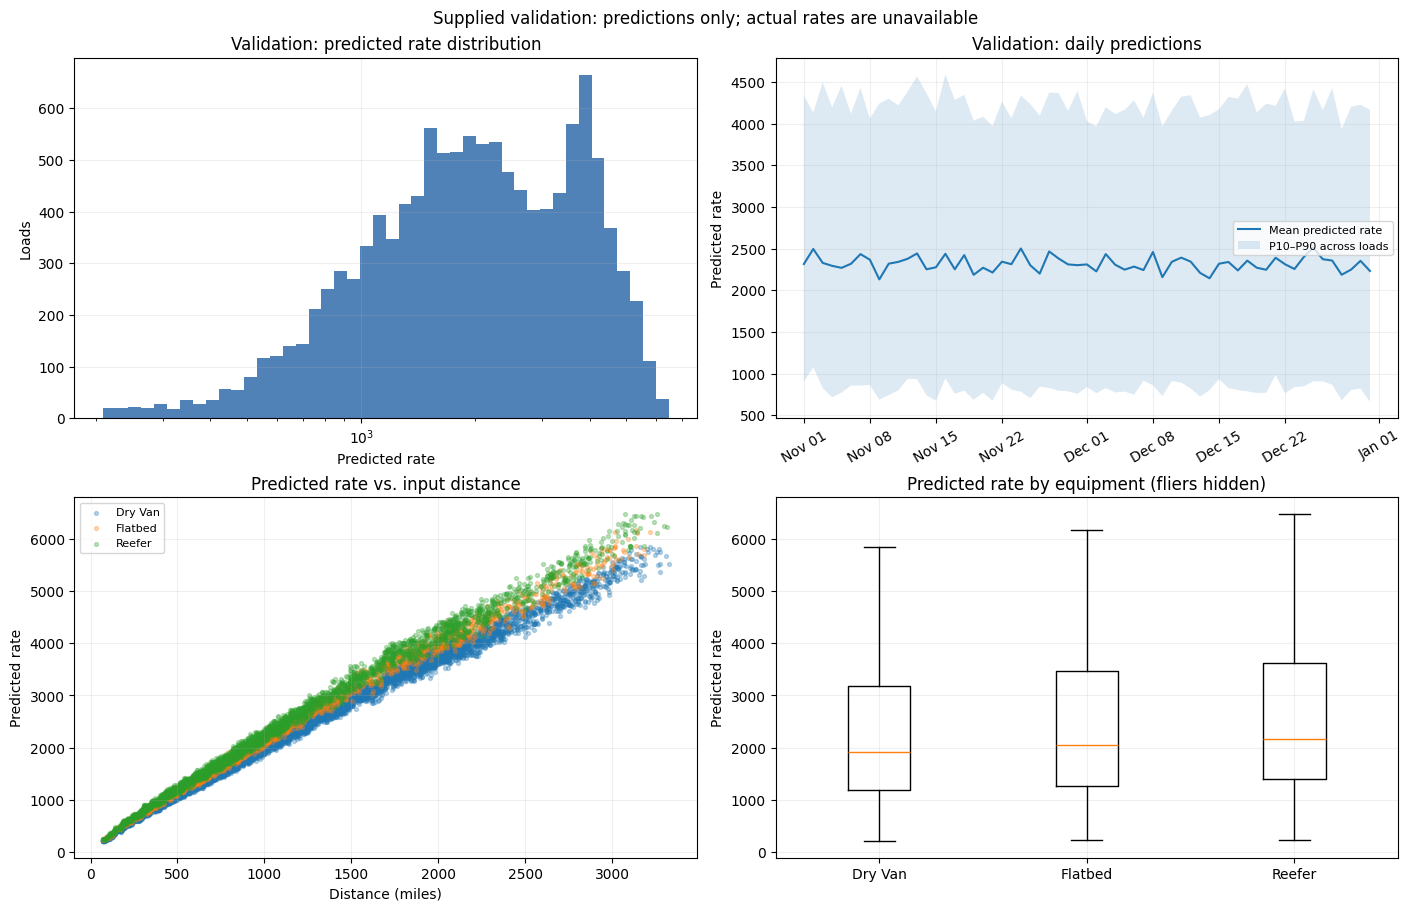

In [3]:
figure = plot_inference_predictions(results)
figure.savefig(output_dir / 'inference-predictions.png', dpi=150, facecolor='white')
plt.show()
plt.close(figure)


In [4]:
submission = template[['load_id']].merge(
    predictions[['load_id', 'predicted_rate']], on='load_id', how='left', validate='one_to_one',
)
assert len(submission) == 12_000 and submission.predicted_rate.notna().all()
submission_path = output_dir / 'validation-predictions.csv'
submission.to_csv(submission_path, index=False)
print(f'Saved predictions: {submission_path.resolve()}')


Saved predictions: /Users/asgatakmaev/Desktop/business/spotter_freight_rate_assessment/outputs/validation-predictions.csv


## December fixed route: reconstruct missing inputs

Use observed city coordinates and same-date/route/Dry Van observations from validation. Fill missing quote signals with a least-squares date line. Fill missing market indices with the saved market equation plus a single vertical shift: `delta = mean(observed_market - fitted_curve)`. All original observations are preserved. The reconstructed inputs feed the saved full-train model below; original assessment inputs remain unchanged.

In [5]:
december_inputs = pd.read_csv(DATA_DIR / 'december-chart-inputs.csv', parse_dates=['date'])
december_prepared = prepare_december_observations(december_inputs, validation)
display(december_prepared[['date', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon',
                           'market_index', 'quote_signal', 'matched_load_ids']])
display(december_prepared[['market_index', 'quote_signal']].isna().sum().rename('Missing days').to_frame())


,date,pickup_lat,pickup_lon,delivery_lat,delivery_lon,market_index,quote_signal,matched_load_ids
0,2025-12-01,36.99152,-84.99876,41.31561,-85.36206,NaN,NaN,
1,2025-12-02,36.99152,-84.99876,41.31561,-85.36206,NaN,NaN,
2,2025-12-03,36.99152,-84.99876,41.31561,-85.36206,NaN,NaN,
3,2025-12-04,36.99152,-84.99876,41.31561,-85.36206,NaN,NaN,
4,2025-12-05,36.99152,-84.99876,41.31561,-85.36206,0.97834,1.92127,TE-006705
5,2025-12-06,36.99152,-84.99876,41.31561,-85.36206,NaN,NaN,
6,2025-12-07,36.99152,-84.99876,41.31561,-85.36206,NaN,NaN,
7,2025-12-08,36.99152,-84.99876,41.31561,-85.36206,NaN,NaN,
8,2025-12-09,36.99152,-84.99876,41.31561,-85.36206,0.92830,2.10398,TE-007537
9,2025-12-10,36.99152,-84.99876,41.31561,-85.36206,NaN,NaN,


,Missing days
market_index,28
quote_signal,28


,Linear quote fit
origin,2025-12-01 00:00:00
intercept,1.859006
slope_per_day,0.024599
observed_points,3
filled_points,28


,date,quote_signal,quote_signal_source,market_index
0,2025-12-01,1.859006,linear extrapolation,NaN
1,2025-12-02,1.883606,linear extrapolation,NaN
2,2025-12-03,1.908205,linear extrapolation,NaN
3,2025-12-04,1.932804,linear extrapolation,NaN
4,2025-12-05,1.921270,observed validation,0.97834
5,2025-12-06,1.982003,linear interpolation,NaN
6,2025-12-07,2.006603,linear interpolation,NaN
7,2025-12-08,2.031202,linear interpolation,NaN
8,2025-12-09,2.103980,observed validation,0.92830
9,2025-12-10,2.080401,linear interpolation,NaN


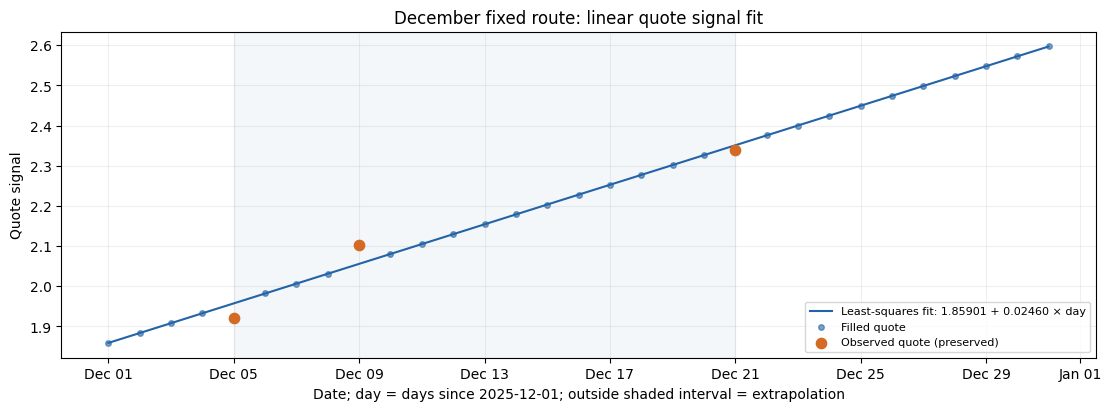

In [6]:
december_prepared, quote_fit = fill_linear_quote_signal(december_prepared)
display(pd.Series(quote_fit, name='Linear quote fit').to_frame())
display(december_prepared[['date', 'quote_signal', 'quote_signal_source', 'market_index']])
quote_figure = plot_quote_signal_fit(december_prepared, quote_fit)
quote_figure.savefig(output_dir / 'december-quote-signal-fit.png', dpi=150, facecolor='white')
plt.show()
plt.close(quote_figure)


,Market vertical shift
vertical_shift,-0.006200
observed_points,3.000000
filled_points,28.000000
observed_fit_rmse,0.019103


,date,market_index,market_index_source,quote_signal
0,2025-12-01,0.832269,base curve + constant shift,1.859006
1,2025-12-02,0.906638,base curve + constant shift,1.883606
2,2025-12-03,0.988247,base curve + constant shift,1.908205
3,2025-12-04,1.015978,base curve + constant shift,1.932804
4,2025-12-05,0.978340,observed validation,1.921270
5,2025-12-06,0.883813,base curve + constant shift,1.982003
6,2025-12-07,0.824290,base curve + constant shift,2.006603
7,2025-12-08,0.836052,base curve + constant shift,2.031202
8,2025-12-09,0.928300,observed validation,2.103980
9,2025-12-10,0.992702,base curve + constant shift,2.080401


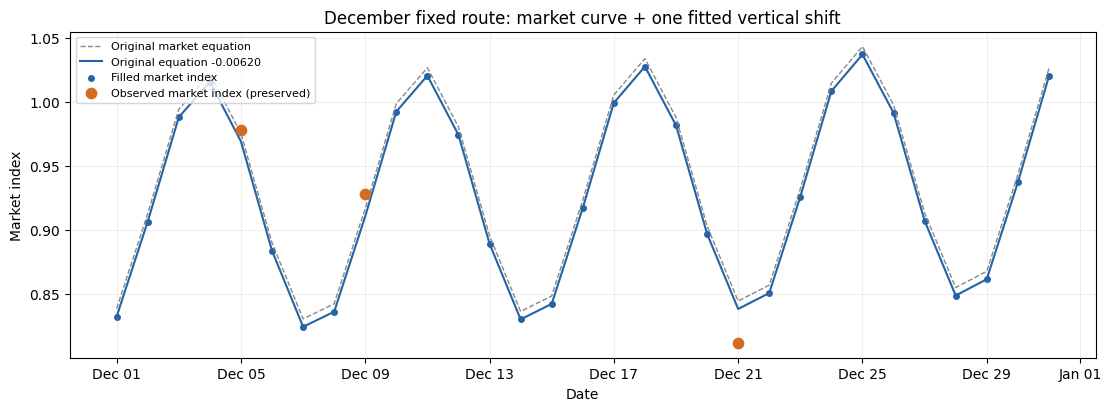

In [7]:
market_curve = bundle['feature_state']['market_encoder'].curve_model
december_prepared, market_shift_fit = fill_shifted_market_index(december_prepared, market_curve)
display(pd.Series(market_shift_fit, name='Market vertical shift').to_frame())
display(december_prepared[['date', 'market_index', 'market_index_source', 'quote_signal']])
market_figure = plot_shifted_market_index(december_prepared, market_shift_fit)
market_figure.savefig(output_dir / 'december-market-index-fit.png', dpi=150, facecolor='white')
plt.show()
plt.close(market_figure)
assert december_prepared[['market_index', 'quote_signal']].notna().all().all()


## December rate predictions and uncertainty

Predict all 31 fixed-route loads with the saved model and preprocessing. The approximate central 90% band uses actual/predicted ratio quantiles from the development-only model's October holdout errors. Applying these to the full-train model and a specific December lane assumes transferable errors; this is not guaranteed 90% coverage. It excludes uncertainty from reconstructing market index and quote signal. The original three observations remain unchanged.

,date,predicted_rate,lower_rate,upper_rate
0,2025-12-01,815.52,782.68,857.65
1,2025-12-02,821.63,788.54,864.07
2,2025-12-03,827.71,794.38,870.47
3,2025-12-04,829.96,796.54,872.84
4,2025-12-05,822.67,789.55,865.18
5,2025-12-06,817.99,785.05,860.25
6,2025-12-07,814.38,781.59,856.45
7,2025-12-08,815.17,782.34,857.28
8,2025-12-09,823.41,790.26,865.95
9,2025-12-10,828.16,794.81,870.95


,Interval calibration
method,held-out empirical actual/predicted quantiles
nominal_coverage,0.9
lower_multiplier,0.959735
upper_multiplier,1.051664
calibration_rows,2183
empirical_calibration_coverage,0.899221
scope,Transferred model-error band; reconstructed-in...
calibration_start,2025-10-18
calibration_end,2025-10-31


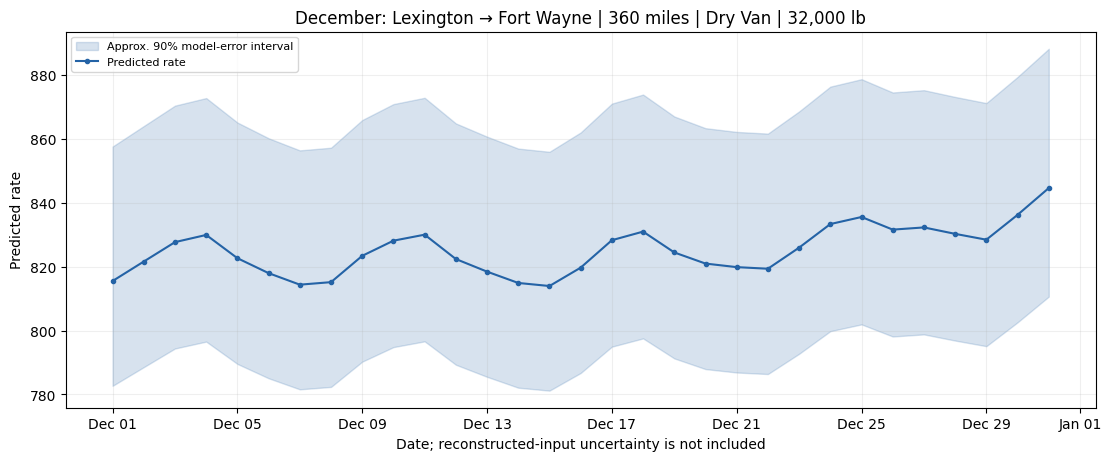

In [8]:
december_for_model = december_prepared.assign(
    load_id=december_prepared.date.dt.strftime('DEC-%Y%m%d'),
)
december_predictions = predict_saved_model(model, december_for_model, bundle, metadata)
interval_calibration = metadata['interval_calibration']
december_predictions = apply_rate_interval(december_predictions, interval_calibration)
display(december_predictions[['date', 'predicted_rate', 'lower_rate', 'upper_rate']].round(2))
display(pd.Series(interval_calibration, name='Interval calibration').to_frame())
december_figure = plot_december_predictions(december_predictions, interval_calibration)
december_figure.savefig(output_dir / 'december-predictions-interval.png', dpi=150, facecolor='white')
plt.show()
plt.close(december_figure)

# Scorer file retains the original seven columns; interval estimates are separate.
december_submission = december_inputs.copy()
december_submission['predicted_rate'] = december_predictions.predicted_rate
december_submission_path = output_dir / 'december-predictions.csv'
december_submission.to_csv(december_submission_path, index=False)
december_predictions[['date', 'predicted_rate', 'lower_rate', 'upper_rate']].to_csv(
    output_dir / 'december-prediction-intervals.csv', index=False,
)


In [10]:
# Validate both deliverables and generate the required December chart.
score_result = subprocess.run(
    [sys.executable, str(notebook_dir.resolve() / 'score.py'),
     '--predictions', str(submission_path.resolve()),
     '--december-predictions', str(december_submission_path.resolve()),
     '--output-dir', str((output_dir / 'scorer_results').resolve())],
    check=True, capture_output=True, text=True,
)
print(score_result.stdout, end='')


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /Users/asgatakmaev/Desktop/business/spotter_freight_rate_assessment/outputs/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.
